# 01 — Analyse exploratoire : qui a survécu au naufrage du Titanic ?

Le 15 avril 1912, le Titanic coule après avoir heurté un iceberg : 1 502 des 2 224 passagers et membres d'équipage périssent. Le jeu de données Kaggle décrit **891 passagers** et indique s'ils ont survécu.

**Question :** quelles caractéristiques des passagers sont associées à la survie, et comment les transformer en variables utiles pour un modèle ?

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / "src").exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
FIG = ROOT / "reports" / "figures"

In [2]:
from titanic.config import load_params
from titanic.data import load_data

df = load_data(load_params())
print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 1. Valeurs manquantes

Cabin       0.771
Age         0.199
Embarked    0.002
dtype: float64

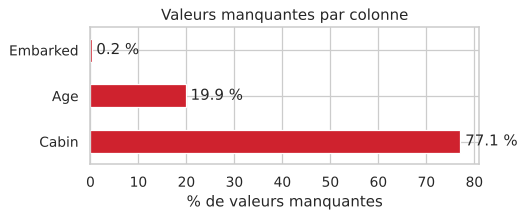

In [3]:
missing = df.isna().mean().sort_values(ascending=False)
missing = missing[missing > 0]
ax = (missing * 100).plot.barh(color="#cf222e", figsize=(6, 2.6))
ax.set_xlabel("% de valeurs manquantes")
ax.set_title("Valeurs manquantes par colonne")
for i, v in enumerate(missing * 100):
    ax.text(v + 1, i, f"{v:.1f} %", va="center")
plt.tight_layout()
missing.round(3)

- **Cabin** (77 % manquant) : trop lacunaire pour être utilisée telle quelle, mais *le fait d'avoir une cabine renseignée* est informatif (surtout 1re classe). → variables `HasCabin` et `Deck` (première lettre).
- **Age** (20 % manquant) : imputé par l'**âge médian du titre** (Mr, Mrs, Miss, Master…), estimé sur le train uniquement.
- **Embarked** (2 valeurs) : imputé par la modalité la plus fréquente.

## 2. Taux de survie global

In [4]:
rate = df["Survived"].mean()
print(f"Taux de survie : {rate:.1%} — un modèle qui prédit toujours « décédé » obtient {1 - rate:.1%} d'accuracy")

Taux de survie : 38.4% — un modèle qui prédit toujours « décédé » obtient 61.6% d'accuracy


## 3. Sexe et classe : les deux facteurs dominants

Sex,female,male
Pclass,,
1,0.968,0.369
2,0.921,0.157
3,0.500,0.135


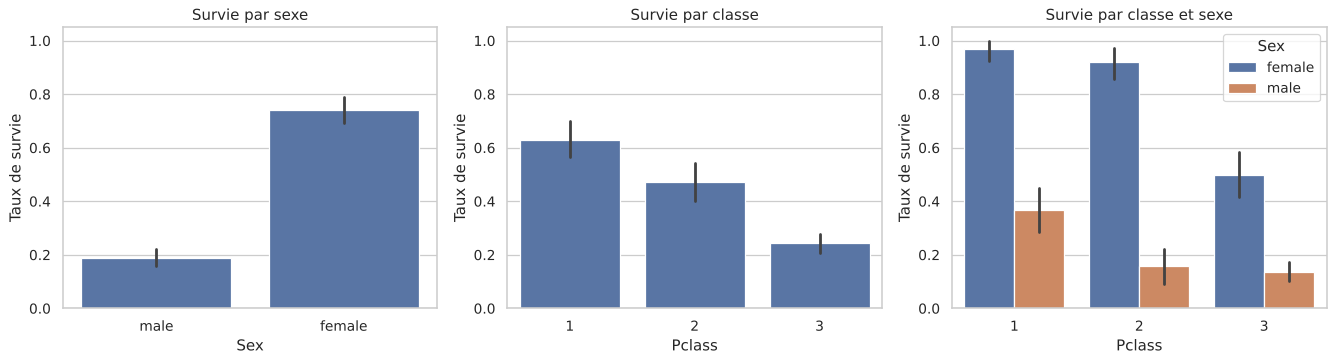

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
sns.barplot(data=df, x="Sex", y="Survived", ax=axes[0], errorbar=("ci", 95))
axes[0].set_title("Survie par sexe")
sns.barplot(data=df, x="Pclass", y="Survived", ax=axes[1], errorbar=("ci", 95))
axes[1].set_title("Survie par classe")
sns.barplot(data=df, x="Pclass", y="Survived", hue="Sex", ax=axes[2], errorbar=("ci", 95))
axes[2].set_title("Survie par classe et sexe")
for ax in axes:
    ax.set_ylabel("Taux de survie")
    ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig(FIG / "eda_sex_class.png", dpi=110)
pd.crosstab(df["Pclass"], df["Sex"], values=df["Survived"], aggfunc="mean").round(3)

La règle « les femmes et les enfants d'abord » est nettement visible : **74 % des femmes ont survécu contre 19 % des hommes**. La classe module fortement cet effet : 97 % des femmes de 1re classe ont survécu, contre 50 % en 3e classe ; chez les hommes, 37 % en 1re classe contre 14 % en 3e.

## 4. Âge

,mean,size
Age,,
"(0, 13]",0.592,71
"(13, 18]",0.412,68
"(18, 30]",0.356,270
"(30, 45]",0.426,202
"(45, 60]",0.407,81
"(60, 81]",0.227,22


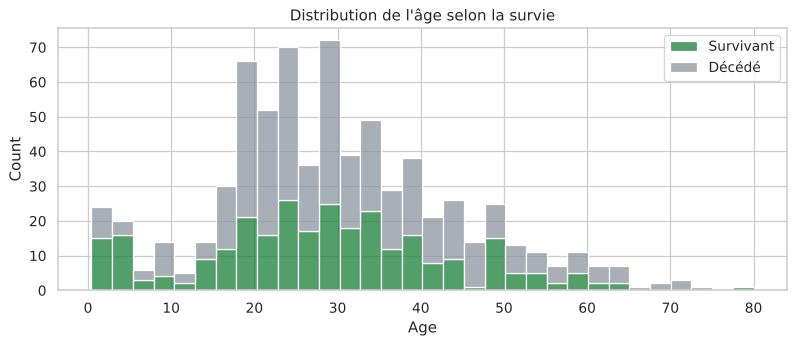

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x="Age", hue="Survived", bins=32, multiple="stack", ax=ax,
             palette={0: "#8c959f", 1: "#1a7f37"})
ax.set_title("Distribution de l'âge selon la survie")
ax.legend(["Survivant", "Décédé"])
plt.tight_layout()
plt.savefig(FIG / "eda_age.png", dpi=110)
age_band = pd.cut(df["Age"], [0, 13, 18, 30, 45, 60, 81])
df.groupby(age_band, observed=True)["Survived"].agg(["mean", "size"]).round(3)

Les enfants de 13 ans ou moins ont un taux de survie nettement supérieur (59 %, contre 36 à 43 % pour les adultes de 18 à 60 ans). Au-delà, l'âge seul est peu discriminant : son effet passe surtout par le sexe et la classe. → variable `IsChild`.

## 5. Le titre extrait du nom

,mean,size
Title,,
Mrs,0.794,126
Miss,0.703,185
Master,0.575,40
Rare,0.348,23
Mr,0.157,517


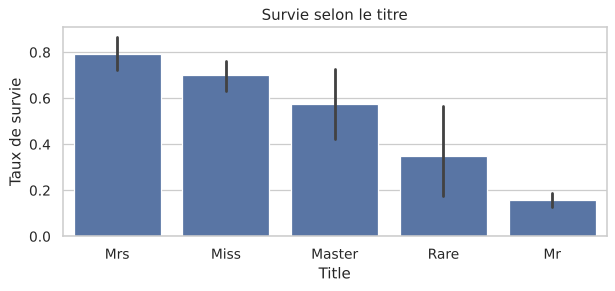

In [7]:
from titanic.features import extract_title

df["Title"] = extract_title(df["Name"])
summary = df.groupby("Title")["Survived"].agg(["mean", "size"]).sort_values("mean", ascending=False).round(3)
fig, ax = plt.subplots(figsize=(7, 3.4))
sns.barplot(data=df, x="Title", y="Survived", order=summary.index, ax=ax, errorbar=("ci", 95))
ax.set_ylabel("Taux de survie")
ax.set_title("Survie selon le titre")
plt.tight_layout()
summary

Le titre combine sexe, âge et statut social : un **Master** est un jeune garçon (≈ 57 % de survie, contre 16 % pour les « Mr »). Il apporte une information que ni `Sex` ni `Age` (souvent manquant) ne donnent seuls.

## 6. Taille de la famille

FamilySize,1,2,3,4,5,6,7,8,11
mean,0.304,0.553,0.578,0.724,0.2,0.136,0.333,0.0,0.0
size,537.000,161.000,102.000,29.000,15.0,22.000,12.000,6.0,7.0


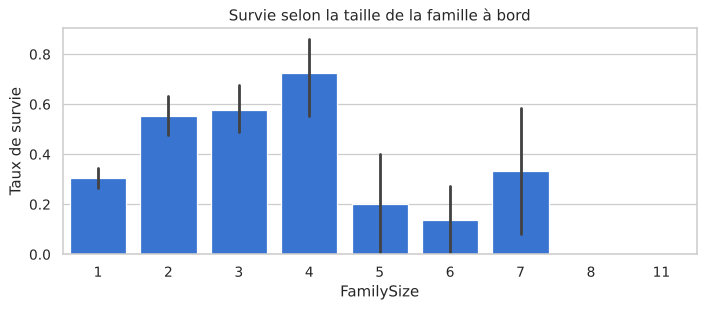

In [8]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.barplot(data=df, x="FamilySize", y="Survived", ax=ax, errorbar=("ci", 95), color="#1f6feb")
ax.set_ylabel("Taux de survie")
ax.set_title("Survie selon la taille de la famille à bord")
plt.tight_layout()
df.groupby("FamilySize")["Survived"].agg(["mean", "size"]).round(3).T

Relation non monotone : les passagers seuls (30 %) et les grandes familles (5 personnes et plus, souvent en 3e classe : 0 à 33 %) survivent moins que les familles de 2 à 4 personnes (55 à 72 %). → `FamilySize` et `IsAlone`.

## 7. Tarif et port d'embarquement

Pclass,1,2,3
Embarked,,,
C,0.51,0.10,0.39
Q,0.03,0.04,0.94
S,0.20,0.25,0.55


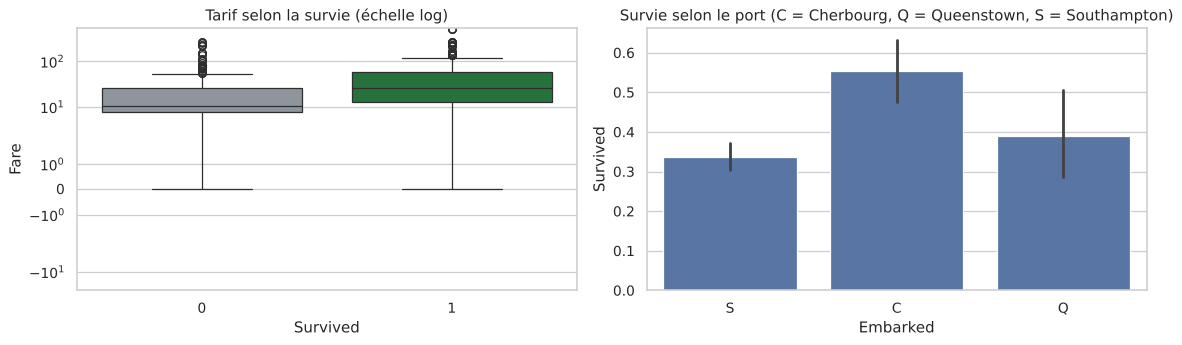

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x="Survived", y="Fare", ax=axes[0], hue="Survived", legend=False, palette=["#8c959f", "#1a7f37"])
axes[0].set_yscale("symlog")
axes[0].set_title("Tarif selon la survie (échelle log)")
sns.barplot(data=df, x="Embarked", y="Survived", ax=axes[1], errorbar=("ci", 95))
axes[1].set_title("Survie selon le port (C = Cherbourg, Q = Queenstown, S = Southampton)")
plt.tight_layout()
pd.crosstab(df["Embarked"], df["Pclass"], normalize="index").round(2)

Le tarif est très asymétrique (de 0 à 512 £) : on utilise `log(1 + Fare)`. L'avantage apparent de Cherbourg s'explique en grande partie par sa forte proportion de passagers de 1re classe (51 %) : c'est un effet de **confusion**, pas un effet causal du port.

## 8. Conclusions pour la modélisation

| Variable créée | Justification |
|---|---|
| `Title` | Combine sexe, âge et statut ; « Master » isole les garçons |
| `Age` imputé par titre | 20 % de valeurs manquantes ; la médiane par titre est bien plus précise que la médiane globale |
| `IsChild` | Priorité donnée aux enfants |
| `FamilySize`, `IsAlone` | Effet non monotone de la taille de la famille |
| `LogFare` | Tarif très asymétrique |
| `HasCabin`, `Deck` | Cabine renseignée ≈ statut social, position sur le navire |

Toutes ces transformations sont codées dans `src/titanic/features.py` comme un transformateur scikit-learn : les quantités apprises (âge médian par titre…) sont estimées **uniquement sur les données d'entraînement**, dans chaque pli de validation croisée.